### Здесь реализован полный цикл от задания геометрии catenary curv аналитическим способом, до построения PSF изображения.

*Note*

1. Параметром N мы определяем количество наслоений ячейки, чем их больше - тем лучше сбор света
2. Параметр N должен быть четным, 0 - 2 - 4 - 6 - 8 - 10
3. Координата без пары - середина симметрии каждого порядка.
4. M - определяет количество порядков. Чем их больше тем больше собирается света. Дальние парядки становятся очень маленького размера.
5. big-center - Определяет количество кривых для первого порядка (самого интенсивного)

In [ ]:
import meep as mp
import numpy as np
import conf
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.interpolate import interp1d
from matplotlib.colors import Normalize

# Параметры симуляции для MEEP
resolution = 25  # разрешение сетки (точек на длину волны)
wavelength = 3.7  # длина волны источника
X_cell_size = conf.cell_X
Y_cell_size = 10*1e3 # 10 mm
cell = mp.Vector3(X_cell_size, Y_cell_size, 0)  # размер области симуляции
pml_layers = [mp.PML(thickness=conf.in_pml, direction=mp.X, side=mp.ALL)]
sources = [mp.Source(
    mp.GaussianSource(conf.inc_fcen, fwidth=conf.inc_df),
    component=mp.Ez,
    center=conf.source_center,
    size=mp.Vector3(x=0, y=Y_cell_size, z=0),
)]

# Все параметры касающиеся определения геометрии
M = 50 # число радиальных слоёв.
big_center = True
N_for_big_center = 20
N = 10
LIMIT_PRODUCT = 0.2 # Ограничение на размер ячейки 



k = 2 * np.pi / wavelength # волновое число
f = 20*1e3 # focal length 10 mm
Q = 200 # детализация
w = 1 # 1000 nm (расстояние промежутка)

if big_center:
    x_sections_coordinates = np.zeros((M,N_for_big_center,4))
else: x_sections_coordinates = np.zeros((M,N+1,4))

geometry = []
# sub
geometry.append(mp.Block(
    material=conf.in_material,
    size=mp.Vector3(conf.in_sub, mp.inf, 0),
    center=mp.Vector3(conf.sub_center),
))

# Precompute radii
rt = np.sqrt(4 * f * (-np.pi / 2 + np.arange(1, M+1) * np.pi) / k)


# Define the function to integrate
def fun(x):
    return np.tan((k * x ** 2) / (4 * f))
def zero_derivative (m):
    calculation = np.sqrt((4 * f * m * np.pi)/k)
    return calculation
def get_y_section(y0, curves):
    """
    Получить срез кривых плоскостью Y = y0.

    :param y0: Значение Y для среза.
    :param curves: Список массивов с координатами кривых [(x1, y1), (x2, y2), ...].
    :return: Координата (x) для пересечения.
    """
    sections = np.zeros(shape=4)
    n=0
    for curve in curves:
        x_vals, y_vals = curve
        x_first_center = 0
        for i in range(len(y_vals) - 1):           
            y1, y2 = y_vals[i], y_vals[i + 1]
            x1, x2 = x_vals[i], x_vals[i + 1]         
            if y1 <= y0 <= y2 or y2 <= y0 <= y1:
                # Линейная интерполяция для x
                x_interp = x1 + (y0 - y1) * (x2 - x1) / (y2 - y1)
                if x_first_center != x_interp: sections[n] = x_interp
                x_first_center = x_interp
                n = n + 1
                
    return sections

# Main loop for layers
for m in range(M):
    rt0 = 0 if m == 0 else rt[m - 1] + 0.1
    x = np.linspace(rt0, rt[m] - 0.01, Q)
    # Compute y values by integration
    y = np.array([quad(fun, rt0, xi)[0] for xi in x])
    yy = np.empty((N_for_big_center, 2), dtype=object)
    
    xt = x.copy()
    ip = np.argmin(y)
    y1 = y - y[ip]
    y11 = y1.copy()
    y2 = y11 - w
    
    print(f"Circle {m}")
    
    if big_center:
        SECTION = w*N_for_big_center
        #Здесь мы собираем все кривые принадлежащие данному порядку
        for n in range(N_for_big_center):
            curves = []
            yy[n, 0] = y1 + 2 * n * w # Верхняя кривая 
            yy[n, 1] = y2 + 2 * n * w # Нижняя кривая
                 
            # Формируем кривые
            curves.append((xt, yy[n,0]))
            curves.append((xt, yy[n,1]))
            
            # Получаем срез при Y = SECTION
            x_sections_coordinates[m, n] = get_y_section(SECTION, curves)
            print(f"Section: {n} :", x_sections_coordinates[m,n])
            
        big_center = False
    
    else:
        SECTION = w*N
        for n in range(N):
            curves = []
            yy[n, 0] = y1 + 2 * n * w # Верхняя кривая 
            yy[n, 1] = y2 + 2 * n * w # Нижняя кривая
                 
            # Формируем кривые
            curves.append((xt, yy[n,0]))
            curves.append((xt, yy[n,1]))
            
            # Получаем срез при Y = SECTION
            x_sections_coordinates[m, n] = get_y_section(SECTION, curves)
            print(f"Section: {n} :", x_sections_coordinates[m,n])
   

Все необходимые мне данные аккумулируются в x_sections_coordinates. Теперь нобходимо их только правильно обработать

In [ ]:
list_of_centers = []
list_of_widths = []

def get_width_first_order(x_sections_coordinates):
    result = []
    for n in range(N_for_big_center): 
        if x_sections_coordinates[0, n, 0] == 0:
            # Добавляем width_first_order
            width_first_order = x_sections_coordinates[0, n, 1] * 2
            result.append(width_first_order)
            return result  # Завершаем функцию сразу после нахождения значения
        else:
            # Вычисляем ширину и добавляем её в список
            width = abs(x_sections_coordinates[0, n, 0] - x_sections_coordinates[0, n, 1])
            result.append(width)

def get_centers_first_order(x_sections_coordinates):
    result = []
    for n in range(N_for_big_center):
        if x_sections_coordinates[0, n, 0] == 0:
            first_center = 0
            result.append(first_center)
            return result
        else:
            another_center = abs(x_sections_coordinates[0, n, 0] + x_sections_coordinates[0, n, 1]) /2
            result.append(another_center)
            
def get_width_other_order(x_sections_coordinates,m):
    result = []
    for n in range(N):
        if (x_sections_coordinates[m,n,0] != 0) and (x_sections_coordinates[m,n,1] == 0) and (x_sections_coordinates[m,n+1,0] == 0):
            third = abs(x_sections_coordinates[m,n,2] - x_sections_coordinates[m,n,3])
            result.append(third)
            return result  
        if x_sections_coordinates[m,n,0] == 0 or x_sections_coordinates[m,n,0] == 0:
            continue
        if x_sections_coordinates[m,n,2] != 0:
            first = abs(x_sections_coordinates[m,n,0] - x_sections_coordinates[m,n,2])
            result.append(first)       
        if x_sections_coordinates[m,n,3] != 0:
            second = abs(x_sections_coordinates[m,n,1] - x_sections_coordinates[m,n,3])
            result.append(second)
          
def get_center_of_other_order(x_sections_coordinates, m):
    result = []
    for n in range(N):
        if (x_sections_coordinates[m,n,0] != 0) and (x_sections_coordinates[m,n,1] == 0) and (x_sections_coordinates[m,n+1,0] == 0):
            center = zero_derivative(m)
            result.append(center)
            return result         
        
        if x_sections_coordinates[m,n,0] == 0 or x_sections_coordinates[m,n,0] == 0:
            continue        
        if x_sections_coordinates[m,n,2] != 0:
            first = (x_sections_coordinates[m,n,0] + x_sections_coordinates[m,n,2])/2
            result.append(first)
        if x_sections_coordinates[m,n,3] != 0:
            second = (x_sections_coordinates[m,n,1] + x_sections_coordinates[m,n,3])/2
            result.append(second) 

for m in range(1,M):
    other_center = get_center_of_other_order(x_sections_coordinates, m)
    other_width = get_width_other_order(x_sections_coordinates, m)
    list_of_centers.append(other_center)
    list_of_widths.append(other_width)

In [ ]:
list_of_centers.insert(0,get_centers_first_order(x_sections_coordinates))
list_of_widths.insert(0,get_width_first_order(x_sections_coordinates))

Геттеры для ширин и центров готовы, теперь можно собрать геометрию.
Основные центры добываются максимально точно. Но вот ширины и центры дополнительных сечений построены на интерполяции, что суммарно может вносить значительные искажения. 

In [90]:
# Тест для проверки основных параметров. Длина ширин на каждом радиусе (на каждом порядке должна равняться длине центров)
for i in range (len(list_of_centers)):
    for j in range(len(list_of_centers[i])):
        if list_of_centers[i][j] != list_of_centers[i][j]:
            ValueError("List elements do not match")
print("Checked")

Checked


In [ ]:
# Функция для рекурсивного обхода всех вложенных списков
def flatten(lst):
    for item in lst:
        if isinstance(item, list):
            # Если элемент - это список, рекурсивно обрабатываем его
            yield from flatten(item)
        else:
            # Если элемент не список, возвращаем его
            yield item

# Получаем все элементы из вложенных списков
flat_centers = list(flatten(list_of_centers))
flat_widths = list(flatten(list_of_widths))
# Зальем теперь это все в геометрию
for i in range(len(flat_centers)):
    if flat_widths[i] < LIMIT_PRODUCT:
        continue
    else:
        geometry.append(mp.Block(
            material=conf.at_material,
            size=mp.Vector3(x=conf.at_hei, y=flat_widths[i], z=0), 
            center=mp.Vector3(x=conf.at_center, y=flat_centers[i], z=0)
        ))
    
    #Another side
    if flat_widths[i] < LIMIT_PRODUCT:
        continue
    else:
        geometry.append(mp.Block(
            material=conf.at_material,
            size=mp.Vector3(x=conf.at_hei, y=flat_widths[i], z=0), 
            center=mp.Vector3(x=conf.at_center, y=-flat_centers[i], z=0)
        ))   

In [ ]:
sim = mp.Simulation(
    cell_size=cell,
    boundary_layers=pml_layers,
    geometry=geometry,
    sources=sources,
    resolution=resolution,
    split_chunks_evenly=False
)


# Добавление near2far области
near2far_region = sim.add_near2far(
    conf.inc_fcen,  # центральная частота
    0,      # ширина спектра
    1,
    mp.Near2FarRegion(center=conf.flux_center, size=mp.Vector3(y=Y_cell_size)),
)

plt.figure(figsize=(1, 150))
sim.plot2D(
    output_plane = mp.Volume(center=mp.Vector3(0,0,0), size=mp.Vector3(cell[0], cell[1],0))
)
plt.savefig("precomp_near_plot.png", dpi = 150)  # Сохранение изображения в файл
plt.show()  # Отображение изображения

In [ ]:
# Запуск симуляции
sim.run(until = 50)

In [ ]:
spot_size = Y_cell_size/2
ff_res = 1000/spot_size
split = spot_size*ff_res
split = int(split)
print(split)

In [ ]:
# Вычисление полей в дальней зоне
far_field = sim.get_farfields(
    near2far_region,
    ff_res,
    center=mp.Vector3(x=conf.flux_center[0] + f),
    size = mp.Vector3(y=spot_size)
)

In [ ]:
Ez_far_field = abs(far_field["Ez"])**2

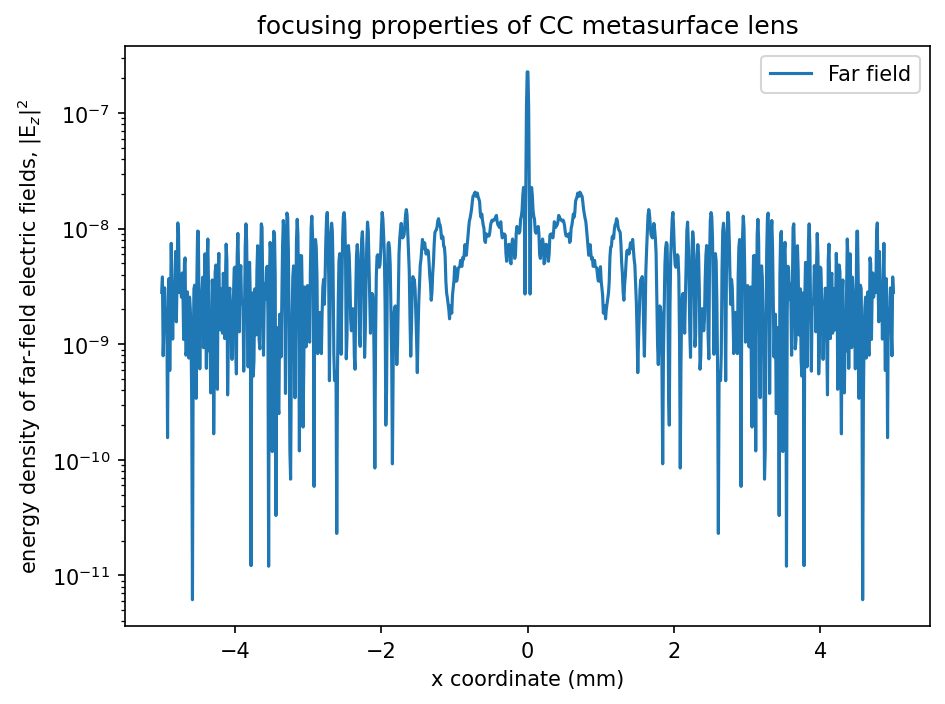

In [92]:
x = np.linspace(
    -spot_size,
    +spot_size,
    split,
)

plt.figure(dpi=150)
plt.semilogy(
    x*1e-3, Ez_far_field, label="Far field"
)
plt.xlabel("x coordinate (mm)")
plt.ylabel(r"energy density of far-field electric fields, |E$_z$|$^2$")
plt.title("focusing properties of CC metasurface lens")
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

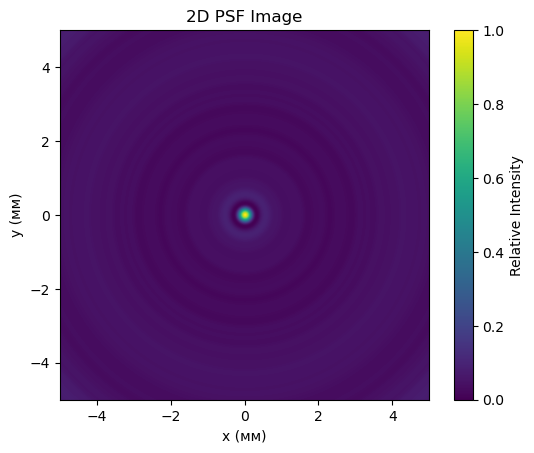

In [96]:
from matplotlib.colors import Normalize
# Интерполяция данных интенсивности для получения значений на любых радиусах
interp_func = interp1d(x, Ez_far_field, kind='cubic', fill_value="extrapolate")

# Размерность изображения должна соотносится с размерностью х, чтобы не терять привязку к реальным размерам
image_size = len(x)
center = image_size // 2

# Создание пустого изображения
image = np.zeros((image_size, image_size))

# Заполнение изображения на основе радиусов
for i in range(image_size):
    for j in range(image_size):
        r = np.sqrt((i - center)**2 + (j - center)**2)  # Вычисление радиуса
        image[i, j] = interp_func(r)  # Применение интерполированной интенсивности

# Нормализация интенсивности в диапазоне от 0 до 1
norm = Normalize(vmin=np.min(image), vmax=np.max(image))
normalized_image = norm(image)

# Визуализация результата
plt.imshow(normalized_image, cmap='viridis', origin='lower', extent=[x[0]*1e-3, x[-1]*1e-3, x[0]*1e-3, x[-1]*1e-3])
plt.colorbar(label='Relative Intensity')
plt.title("2D PSF Image")
plt.xlabel("x (мм)")
plt.ylabel("y (мм)")
plt.show()